# NumPy – obliczenia numeryczne w Pythonie

**Cele lekcji.** Po tym notatniku będziesz potrafić:
- wyjaśnić, czym tablica `ndarray` różni się od listy Pythona i dlaczego jest szybsza,
- tworzyć tablice oraz sprawdzać ich kształt i typ (`shape`, `dtype`),
- indeksować, wycinać i filtrować dane (maski logiczne),
- wykonywać operacje wektorowe i agregacje, korzystać z broadcastingu,
- mnożyć macierze – operację, na której opierają się modele ML.

**Plan:** 1. Dlaczego NumPy? · 2. Tworzenie tablic i losowanie · 3. Typy danych · 4. Indeksowanie i wycinki · 5. Kształt tablic · 6. Operacje i funkcje uniwersalne · 7. Broadcasting · 8. Agregacje · 9. Maski, indeksowanie zaawansowane, sortowanie · 10. Mnożenie macierzy · 11. Typowe pułapki

## Czym jest NumPy?

NumPy (*Numerical Python*) to podstawowa biblioteka do obliczeń numerycznych w Pythonie. Opierają się na niej Pandas, SciPy, Matplotlib i scikit-learn – dane trafiają do modeli ML najczęściej właśnie jako tablice NumPy.

- **tablice wielowymiarowe** (`ndarray`) – jednorodne i zwarte w pamięci,
- **operacje wektorowe** – działania na całych tablicach bez pętli, wykonywane w szybkim kodzie C,
- **indeksowanie, wycinanie i maski logiczne**,
- **generatory liczb losowych**,
- **algebra liniowa** (`np.linalg`).

Dokumentacja: https://numpy.org/doc/ · Instalacja: `pip install numpy` · Typowy import:

In [1]:
import numpy as np
np.__version__

'2.4.6'

## 1. Dlaczego NumPy? Lista a tablica

In [4]:
lista = [1, 2, 3]
lista

[1, 2, 3]

In [5]:
arr = np.array(lista)
arr

array([1, 2, 3])

In [10]:
lista * 2

[1, 2, 3, 1, 2, 3]

In [11]:
arr * 2

array([2, 4, 6])

In [2]:
lista = [1, 2, 3]
arr = np.array(lista)

print("lista * 2     :", lista * 2)      # powtórzenie listy
print("arr * 2       :", arr * 2)        # mnożenie każdego elementu
print("lista + lista :", lista + lista)  # sklejenie list
print("arr + arr     :", arr + arr)      # dodawanie element po elemencie

lista * 2     : [1, 2, 3, 1, 2, 3]
arr * 2       : [2 4 6]
lista + lista : [1, 2, 3, 1, 2, 3]
arr + arr     : [2 4 6]


Lista i tablica wyglądają podobnie (nawiasy `[]`, indeksy, wycinki), ale **operatory działają inaczej**: na tablicach wykonują się element po elemencie (*wektoryzacja*). Sprawdźmy też szybkość – dodajemy do siebie dwa ciągi po milion liczb:

In [13]:
n = 1_000_000
lista_a, lista_b = list(range(n)), list(range(n, 2 * n))
arr_a, arr_b = np.arange(n), np.arange(n, 2 * n)

In [16]:
%timeit [a + b for a, b in zip(lista_a, lista_b)]

28.3 ms ± 1.27 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [17]:
%timeit arr_a + arr_b

713 μs ± 310 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


Tablica jest zwykle **wielokrotnie szybsza** (tu: ok. 100×), bo pętla wykonuje się w skompilowanym kodzie C, a dane leżą w jednym ciągłym bloku pamięci. Zajmuje też mniej pamięci:

In [19]:
import sys

lista = list(range(1000))
arr = np.arange(1000)

pamiec_listy = sys.getsizeof(lista) + sum(sys.getsizeof(x) for x in lista)
print("Lista  :", pamiec_listy, "B")
print("Tablica:", arr.nbytes, "B danych +", sys.getsizeof(arr) - arr.nbytes, "B narzutu obiektu")

Lista  : 36056 B
Tablica: 8000 B danych + 112 B narzutu obiektu


**Wniosek.** Lista przechowuje wskaźniki do osobnych obiektów Pythona (każda liczba to pełnoprawny obiekt z metadanymi). Tablica NumPy przechowuje same wartości **jednego typu** w ciągłym bloku pamięci – jak tablica w języku C. Stąd szybkość i mała zajętość pamięci; ceną jest jednorodność typu.

## 2. Tworzenie tablic i losowanie

### `np.ndarray`


* Reprezentuje jedno lub wielowymiarową tablicę wartości. Jest to podstawowa klasa definiowana przez bibliotekę.
* Wszystkie wartości w tablicy musza być tego samego typu, czyli `np.ndarray` jest tablicą jednorodną (homogeniczną) .
* Każda wartość zajmuje tę samą określoną przez typ porcję pamięci.

### `np.array()`

Tworzy tablice z "tablicopodobnych" obiektów, np. z list:

In [24]:
l = [1.2, 2, 'tekst', True]
l

[1.2, 2, 'tekst', True]

In [26]:
a = np.array([1, 2, 3])
a

array([1, 2, 3])

In [27]:
type(a)

numpy.ndarray

In [28]:
type(l)

list

### Atrybuty tablic

* `.ndim` -- liczba wymiarów, liczba całkowita.
* `.shape` -- rozmiar każdego z wymiarów, krotka liczb całkowitych.
* `.size` -- całkowita liczba wartości, iloczyn wartości z krotki `.shape`.

In [34]:
a = np.arange(-10, 11, 2)
a

array([-10,  -8,  -6,  -4,  -2,   0,   2,   4,   6,   8,  10])

In [35]:
a.ndim, a.shape, a.size

(1, (11,), 11)

### Funkcje tworzące tablice

`np.zeros()`, `np.ones()`, `np.full()`, `np.arange()`, `np.linspace()`, `np.eye()` oraz generatory liczb losowych (poniżej).

Tablica dwuwymiarowa o 6 elementach, 3 wiersze i dwie kolumny:

In [48]:
np.full(fill_value=3, shape=(2,2))

array([[3, 3],
       [3, 3]])

In [44]:
a = np.zeros((3, 5))
a

array([[0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0.]])

In [45]:
a.ndim, a.shape, a.size
# ndim - liczba wymiarów, liczba całkowita
# shape - rozmiar każdego z wymiarów, krotka liczb całkowitych 
# size całkowita liczba wartości, iloczyn wartości z krotki shape

(2, (3, 5), 15)

Tablica trójwymiarowa o 12 elementach, wymiary osi 3x2x2:

In [46]:
a = np.full((3, 2, 2), 100)
a

array([[[100, 100],
        [100, 100]],

       [[100, 100],
        [100, 100]],

       [[100, 100],
        [100, 100]]])

In [49]:
a.ndim, a.shape, a.size

(3, (3, 2, 2), 12)

In [50]:
np.zeros(shape=(4, 10)) # np. tworzenie czarnej maski do zdjęć (techniki Computer Vision)

array([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]])

In [51]:
np.ones(shape=(5, 5))

array([[1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1.]])

In [52]:
np.full(shape=(3, 3), fill_value=4, dtype='int')

array([[4, 4, 4],
       [4, 4, 4],
       [4, 4, 4]])

In [53]:
np.arange(10) # wygenerowanie danych od 0 do 10 (tak jak range w Pythonie)

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

In [54]:
np.arange(start=5, stop=10)# dlaczego na końcu mamy 9 a nie 10? pytanie kontrolne

array([5, 6, 7, 8, 9])

In [55]:
np.arange(start=10, stop=100, step=10) 

array([10, 20, 30, 40, 50, 60, 70, 80, 90])

In [56]:
np.arange(start=100, stop=10, step=-10)

array([100,  90,  80,  70,  60,  50,  40,  30,  20])

In [57]:
np.arange(start=0, stop=1, step=0.05)

array([0.  , 0.05, 0.1 , 0.15, 0.2 , 0.25, 0.3 , 0.35, 0.4 , 0.45, 0.5 ,
       0.55, 0.6 , 0.65, 0.7 , 0.75, 0.8 , 0.85, 0.9 , 0.95])

In [64]:
np.linspace(start=1, stop=1000, num=10) # num to liczba elementów z przedziału <start:stop> równo rozłożonych

array([   1.,  112.,  223.,  334.,  445.,  556.,  667.,  778.,  889.,
       1000.])

Macierz jednostkowa (jedynki na przekątnej) i macierz z podanym wektorem na przekątnej:

In [65]:
np.eye(4, dtype='int')

array([[1, 0, 0, 0],
       [0, 1, 0, 0],
       [0, 0, 1, 0],
       [0, 0, 0, 1]])

In [66]:
np.diag([1, 2, 3])

array([[1, 0, 0],
       [0, 2, 0],
       [0, 0, 3]])

Tablice o takim samym kształcie i typie jak istniejąca tablica: `np.zeros_like()`, `np.ones_like()`, `np.full_like()`:

In [68]:
np.array([[1.5, 2.5], [3.5, 4.5]])

array([[1.5, 2.5],
       [3.5, 4.5]])

In [67]:
wzor = np.array([[1.5, 2.5], [3.5, 4.5]])
np.zeros_like(wzor), np.full_like(wzor, 9.99)

(array([[0., 0.],
        [0., 0.]]),
 array([[9.99, 9.99],
        [9.99, 9.99]]))

### Liczby pseudolosowe

Generatory losowe są wszędzie w ML: podział na zbiór treningowy i testowy, inicjalizacja wag sieci, symulacje. Liczby są **pseudolosowe** – tworzy je deterministyczny algorytm, więc po ustawieniu tego samego ziarna (*seed*) dostajemy zawsze ten sam ciąg. Dzięki temu eksperymenty są **powtarzalne**.

W nowym kodzie używamy generatora `np.random.default_rng(seed)`. Starszy styl (`np.random.seed()`, `np.random.rand()`) nadal działa i często pojawia się w tutorialach, ale zalecany jest `Generator`.

In [104]:
np.random.random()

0.6575862352222713

In [77]:
rng = np.random.default_rng(seed=42)  # ten sam seed -> te same liczby
rng

Generator(PCG64) at 0x1134B0040

In [127]:
rng = np.random.default_rng(seed=41)
rng.random()  # rozkład jednostajny na [0, 1)

0.9541511029620046

In [129]:
rng.random((3, 2))  # tablica 3x2

array([[0.60249991, 0.33883591],
       [0.6218064 , 0.73248467],
       [0.86108828, 0.33782439]])

In [132]:
rng.standard_normal(5)  # rozkład normalny N(0, 1)

array([ 0.36928103,  0.56826546,  0.78350766, -0.6304341 , -0.22179646])

In [133]:
rng.normal(loc=170, scale=10, size=5)  # N(średnia=170, odch. std.=10), np. wzrost w cm

array([189.72353403, 168.14031939, 170.29913095, 174.40948251,
       164.22739448])

In [139]:
rng.integers(low=10, high=101, size=10)  # liczby całkowite z przedziału [10, 101)

array([10, 36, 26, 45, 34, 85, 23, 83, 26, 14])

In [149]:
rng.choice(['python', 'java', 'sql'])  # losowy element

np.str_('python')

Losowanie bez powtórzeń (parametr `replace=False`), np. numery w losowaniu lotto:

In [158]:
rng.choice(np.arange(1, 50), size=6, replace=False)

array([46, 37, 43, 36, 47, 31])

In [166]:
dane = np.arange(10)
rng.permutation(dane)  # nowa, przetasowana tablica (rng.shuffle(dane) tasuje „w miejscu”)

array([9, 7, 1, 5, 0, 2, 8, 3, 6, 4])

W scikit-learn odpowiednikiem ziarna jest parametr `random_state` (np. w `train_test_split`).

## 3. Typy danych (`dtype`)

### `dtype`

Wspólny typ dla wszystkich wartości w tablicy:

In [167]:
a = np.array([1, 2, 3])
a.dtype

dtype('int64')

In [168]:
a = np.array([1.5, 2, 3.14])
a.dtype

dtype('float64')

Automatyczne rozszerzanie typu:

In [169]:
a = np.array([1, 2, 3, 4.5])
a

array([1. , 2. , 3. , 4.5])

In [170]:
a.dtype

dtype('float64')

Zadawanie konkretnego typu:

In [171]:
a = np.array([1, 2, 3], dtype='float64')
a

array([1., 2., 3.])

In [172]:
a.dtype

dtype('float64')

Zawężanie typu:

In [179]:
np.ceil(1.1)

np.float64(2.0)

In [ ]:
a = np.array([1.6, 2.1, 3.0])
a

array([1, 2, 3], dtype=int32)

In [184]:
a = np.array([1.6, 2.1, 3.0])
a = np.ceil(a).astype('int32')

a

array([2, 3, 3], dtype=int32)

In [191]:
a = np.array([1.6, 2.1, 3], dtype='int32')
a

array([1, 2, 3], dtype=int32)

In [192]:
np.round(1.5)

np.float64(2.0)

In [198]:
a = np.array([1.6, 2.1, 3.0])
a = np.round(a).astype("int32")

a

array([2, 2, 3], dtype=int32)

In [199]:
a.dtype

dtype('int32')

### Najczęściej używane typy

| Typ | Opis | Typowe zastosowanie |
|---|---|---|
| `bool` | prawda / fałsz | maski logiczne |
| `int32`, `int64` | liczby całkowite | liczniki, indeksy |
| `uint8` | liczby całkowite 0–255 | piksele obrazów |
| `float32` | liczby rzeczywiste, 32 bity | sieci neuronowe, GPU (mniej pamięci) |
| `float64` | liczby rzeczywiste, 64 bity | domyślny typ dla liczb rzeczywistych |

Pełna lista typów: https://numpy.org/doc/stable/reference/arrays.scalars.html

### Rozmiar w pamięci: `itemsize` i `nbytes`

- `a.itemsize` – rozmiar jednego elementu w bajtach,
- `a.nbytes` – rozmiar wszystkich danych tablicy (`a.size * a.itemsize`).

In [200]:
a = np.array(range(10), dtype=np.int64)
a

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

In [201]:
a.itemsize, a.nbytes  # 10 wartości x 8 bajtów

(8, 80)

#### `.astype()`

Metoda konwertująca typ, zwraca kopię tablicy:

In [202]:
b = a.astype('int16')
b

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=int16)

In [203]:
b.itemsize, b.nbytes  # 10 wartości x 2 bajty

(2, 20)

**Uwaga:** zawężanie typu nie zgłasza błędu, a może po cichu zmienić wartości (*przepełnienie*, ang. overflow):

In [206]:
np.array([100, 200, 300]).astype('int8')  # int8 mieści liczby od -128 do 127

array([100, -56,  44], dtype=int8)

In [210]:
a = np.array([0, 127, 255], dtype=np.uint8)
a

array([  0, 127, 255], dtype=uint8)

---

### Czas na zadania 1–10

Otwórz notatnik `Zadania/1-10.ipynb` i rozwiąż ćwiczenia 1–10 (zakres: tworzenie tablic i typy danych, sekcje 2–3).

---

## 4. Indeksowanie i wycinki

### Indeksowanie: dostęp do pojedynczych elementów

In [211]:
a = np.arange(10, 20)
a

array([10, 11, 12, 13, 14, 15, 16, 17, 18, 19])

In [212]:
a[0], a[1], a[-1], a[-2]

(np.int64(10), np.int64(11), np.int64(19), np.int64(18))

In [217]:
a = np.array([[ 0,  1,  2,  3,  4],
              [ 5,  6,  7,  8,  9],
              [10, 11, 12, 13, 14],
              [15, 16, 17, 18, 19]])
a

array([[ 0,  1,  2,  3,  4],
       [ 5,  6,  7,  8,  9],
       [10, 11, 12, 13, 14],
       [15, 16, 17, 18, 19]])

In [219]:
a[0,0]

np.int64(0)

In [220]:
a[2,3] # wartośc 13

np.int64(13)

In [221]:
a[-1, -1]

np.int64(19)

### Wycinki

Składnia dla wycinków naśladuje tę wbudowaną w Pythona:

```python
a[start:stop:step]
```

#### Tablice jednowymiarowe

In [222]:
a = np.arange(10)
a

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

In [223]:
a[:3], a[3:]

(array([0, 1, 2]), array([3, 4, 5, 6, 7, 8, 9]))

In [224]:
a[-2:]

array([8, 9])

In [229]:
a[::2]

array([0, 2, 4, 6, 8])

In [230]:
a[1::2]

array([1, 3, 5, 7, 9])

In [231]:
a[::-1]

array([9, 8, 7, 6, 5, 4, 3, 2, 1, 0])

#### Tablice wielowymiarowe

In [232]:
a = np.array([[ 0,  1,  2,  3,  4],
              [ 5,  6,  7,  8,  9],
              [10, 11, 12, 13, 14],
              [15, 16, 17, 18, 19]])
a

array([[ 0,  1,  2,  3,  4],
       [ 5,  6,  7,  8,  9],
       [10, 11, 12, 13, 14],
       [15, 16, 17, 18, 19]])

In [233]:
#Dwa pierwsze wiersze:
a[:2]

array([[0, 1, 2, 3, 4],
       [5, 6, 7, 8, 9]])

Wycinki można tworzyć na każdej osi osobno. Dwa ostatnie wiersze, druga, trzecia i czwarta kolumna:

In [235]:
a

array([[ 0,  1,  2,  3,  4],
       [ 5,  6,  7,  8,  9],
       [10, 11, 12, 13, 14],
       [15, 16, 17, 18, 19]])

In [234]:
a[-2:, 1:4]

array([[11, 12, 13],
       [16, 17, 18]])

#### Wiersze i kolumny

Drugi wiersz:

In [239]:
a[1, :]

array([5, 6, 7, 8, 9])

Lub tak

In [240]:
a[1]

array([5, 6, 7, 8, 9])

ale tak jest mniej czytelnie, bo struktura tablicy pozostaje ukryta. Ponadto, to wywołanie zadziała również dla tablicy jednowymiarowej, co może prowadzić do niespodziewanych błędów.

Trzecia kolumna:

In [241]:
a[:, 2]

array([ 2,  7, 12, 17])

### Przypisanie do wycinka

Do wycinka można przypisać wartość (lub tablicę o pasującym kształcie) – zmieniamy wtedy wszystkie wybrane elementy naraz:

In [244]:
z = np.zeros((4, 5), dtype=int)
z

array([[0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0]])

In [245]:
z[::2, ::2] = 7 

In [246]:
z

array([[7, 0, 7, 0, 7],
       [0, 0, 0, 0, 0],
       [7, 0, 7, 0, 7],
       [0, 0, 0, 0, 0]])

In [247]:
z[:, -1] = 1 

In [248]:
z

array([[7, 0, 7, 0, 1],
       [0, 0, 0, 0, 1],
       [7, 0, 7, 0, 1],
       [0, 0, 0, 0, 1]])

In [ ]:
z = np.zeros((4, 5), dtype=int)
z[::2, ::2] = 7   # co drugi wiersz i co druga kolumna
z[:, -1] = 1      # cała ostatnia kolumna
z

### Uwaga: wycinki to widoki, nie kopie!

**Wycinki tablic NumPy nie tworzą kopii** – zmiana wycinka zmienia tablicę źródłową.

In [249]:
a

array([[ 0,  1,  2,  3,  4],
       [ 5,  6,  7,  8,  9],
       [10, 11, 12, 13, 14],
       [15, 16, 17, 18, 19]])

In [250]:
b = a[1:3, 2:4]
b

array([[ 7,  8],
       [12, 13]])

In [251]:
b[1, 1] = 123
b

array([[  7,   8],
       [ 12, 123]])

In [252]:
a

array([[  0,   1,   2,   3,   4],
       [  5,   6,   7,   8,   9],
       [ 10,  11,  12, 123,  14],
       [ 15,  16,  17,  18,  19]])

### Tworzenie kopii

Jeśli chcemy pracować na niezależnych danych, używamy `.copy()`:

In [253]:
b = a[1:3, 2:4].copy()
b

array([[  7,   8],
       [ 12, 123]])

In [254]:
b[1, 1] = 13
b

array([[ 7,  8],
       [12, 13]])

In [255]:
a

array([[  0,   1,   2,   3,   4],
       [  5,   6,   7,   8,   9],
       [ 10,  11,  12, 123,  14],
       [ 15,  16,  17,  18,  19]])

---

### Czas na zadania 11–20

Otwórz notatnik `Zadania/11-20.ipynb` i rozwiąż ćwiczenia 11–20 (zakres: liczby losowe, indeksowanie, wycinki, widoki i kopie, sekcje 2 i 4).

---

## 5. Kształt tablic: `reshape`, `newaxis`, łączenie

### `.reshape()` -- zmiana kształtu tablicy

In [257]:
np.arange(10)

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

In [259]:
np.arange(10).reshape(2, 5)

array([[0, 1, 2, 3, 4],
       [5, 6, 7, 8, 9]])

In [260]:
np.arange(10).reshape(5, 2)

array([[0, 1],
       [2, 3],
       [4, 5],
       [6, 7],
       [8, 9]])

Wartość `-1` oznacza „wyliczone automatycznie” (może wystąpić tylko raz):

In [267]:
A = np.arange(15)
A

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14])

In [268]:
A.reshape((3, -1)) # -1 tam gdzie nie chcemy liczyć jednego z wymiarów (bardzo długa tablica)

array([[ 0,  1,  2,  3,  4],
       [ 5,  6,  7,  8,  9],
       [10, 11, 12, 13, 14]])

In [269]:
A.reshape((-1, 3)) 

array([[ 0,  1,  2],
       [ 3,  4,  5],
       [ 6,  7,  8],
       [ 9, 10, 11],
       [12, 13, 14]])

Zmiana jednowymiarowej tablicy na dwuwymiarowy wiersz lub kolumnę:

In [275]:
np.arange(10)

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

In [273]:
np.arange(10).shape

(10,)

In [274]:
np.arange(10).reshape(1, 10) # Wiersz

array([[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]])

In [271]:
np.arange(10).reshape(10, 1) # Kolumna

array([[0],
       [1],
       [2],
       [3],
       [4],
       [5],
       [6],
       [7],
       [8],
       [9]])

To samo za pomocą `np.newaxis`:

In [276]:
a = np.arange(10)
a

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

In [277]:
a[np.newaxis, :]

array([[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]])

In [278]:
a[:, np.newaxis]

array([[0],
       [1],
       [2],
       [3],
       [4],
       [5],
       [6],
       [7],
       [8],
       [9]])

In [279]:
# w zależności od potrzeb:
np.arange(5).reshape(5, 1, 1)

array([[[0]],

       [[1]],

       [[2]],

       [[3]],

       [[4]]])

### Wypłaszczanie i transpozycja

`.ravel()` zamienia tablicę na jednowymiarową, `.T` zamienia wiersze z kolumnami.

In [280]:
A = np.arange(20).reshape(4, 5)
A

array([[ 0,  1,  2,  3,  4],
       [ 5,  6,  7,  8,  9],
       [10, 11, 12, 13, 14],
       [15, 16, 17, 18, 19]])

In [281]:
A.ravel()

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19])

In [282]:
A

array([[ 0,  1,  2,  3,  4],
       [ 5,  6,  7,  8,  9],
       [10, 11, 12, 13, 14],
       [15, 16, 17, 18, 19]])

In [283]:
A.T

array([[ 0,  5, 10, 15],
       [ 1,  6, 11, 16],
       [ 2,  7, 12, 17],
       [ 3,  8, 13, 18],
       [ 4,  9, 14, 19]])

### Łączenie i dzielenie tablic

`np.vstack()` (jedna pod drugą), `np.hstack()` (obok siebie), `np.concatenate()` (ogólna wersja, parametr `axis`), `np.split()` (podział na części).

In [284]:
a = np.array([[1, 2], [3, 4]])
b = np.array([[5, 6], [7, 8]])

In [285]:
np.vstack([a, b])

array([[1, 2],
       [3, 4],
       [5, 6],
       [7, 8]])

In [286]:
np.hstack([a, b])

array([[1, 2, 5, 6],
       [3, 4, 7, 8]])

In [291]:
np.concatenate([a, b], axis=1)  # to samo co vstack

array([[1, 2, 5, 6],
       [3, 4, 7, 8]])

In [294]:
np.arange(9)

array([0, 1, 2, 3, 4, 5, 6, 7, 8])

In [292]:
np.split(np.arange(9), 3)  # podział na 3 równe części

[array([0, 1, 2]), array([3, 4, 5]), array([6, 7, 8])]

In [295]:
np.split(np.arange(10), [7])  # podział w wybranym punkcie: wiersze [0:7] i [7:] (np. zbiór treningowy i testowy)

[array([0, 1, 2, 3, 4, 5, 6]), array([7, 8, 9])]

`np.column_stack()` skleja jednowymiarowe wektory jako **kolumny** nowej tablicy dwuwymiarowej:

In [296]:
cecha1 = np.array([1.6, 0.9, 2.2])
cecha2 = np.array([0.4, 1.3, 3.2])
np.column_stack((cecha1, cecha2))  # kształt (3, 2)

array([[1.6, 0.4],
       [0.9, 1.3],
       [2.2, 3.2]])

---

### Czas na zadania 21–30

Otwórz notatnik `Zadania/21-30.ipynb` i rozwiąż ćwiczenia 21–30 (zakres: zmiana kształtu i łączenie tablic, sekcja 5).

---

## 6. Operacje na tablicach i funkcje uniwersalne (ufuncs)

Operatory `+`, `-`, `*`, `/`, `**` działają na tablicach **element po elemencie** (odpowiadają im funkcje `np.add`, `np.subtract`, `np.multiply`, `np.divide`, `np.power`).

*Funkcja uniwersalna* (ufunc) to funkcja zastosowana automatycznie do wszystkich elementów tablicy (wektoryzacja), np. `np.sqrt`, `np.exp`, `np.sin`. Ufuncs są bardzo wydajne.

In [297]:
x = np.arange(5)
y = np.arange(10, 15)
x, y

(array([0, 1, 2, 3, 4]), array([10, 11, 12, 13, 14]))

In [302]:
x + y

array([10, 12, 14, 16, 18])

In [303]:
x * y

array([ 0, 11, 24, 39, 56])

In [304]:
x / y

array([0.        , 0.09090909, 0.16666667, 0.23076923, 0.28571429])

In [305]:
2*x + y/2

array([ 5. ,  7.5, 10. , 12.5, 15. ])

In [306]:
np.sqrt(np.array([1, 4, 9, 16])), np.exp(1)  # pierwiastek, liczba e

(array([1., 2., 3., 4.]), np.float64(2.718281828459045))

Zaokrąglanie i wartość bezwzględna: `np.round()` (parametr `decimals` to liczba miejsc po przecinku) oraz `np.abs()`.

In [316]:
x = np.array([3.14159, -2.71828, 1.41421])
np.round(x,2)

array([ 3.14, -2.72,  1.41])

In [317]:
np.abs(x)

array([3.14159, 2.71828, 1.41421])

Narysujemy wykres funkcji $y=\sin x$ na przedziale $[-2\pi, 2\pi]$:

In [333]:
np.linspace(-2 * np.pi, 2 * np.pi, 10) 

array([-6.28318531, -4.88692191, -3.4906585 , -2.0943951 , -0.6981317 ,
        0.6981317 ,  2.0943951 ,  3.4906585 ,  4.88692191,  6.28318531])

In [336]:
np.sin(np.linspace(-2 * np.pi, 2 * np.pi, 10) )

array([ 2.44929360e-16,  9.84807753e-01,  3.42020143e-01, -8.66025404e-01,
       -6.42787610e-01,  6.42787610e-01,  8.66025404e-01, -3.42020143e-01,
       -9.84807753e-01, -2.44929360e-16])

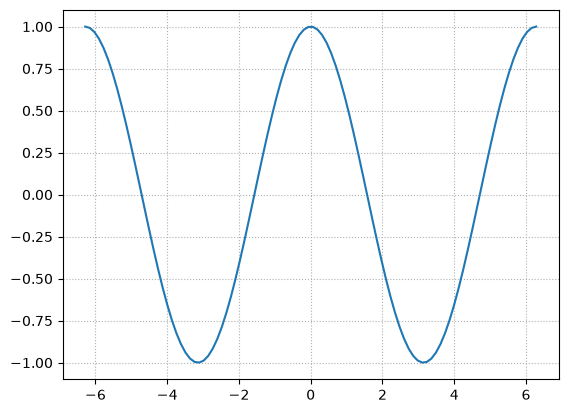

In [332]:
from matplotlib import pyplot as plt

X = np.linspace(-2 * np.pi, 2 * np.pi, 100)  # 100 równo rozmieszczonych punktów
Y = np.cos(X)                                # ufunc działa na całej tablicy naraz
plt.plot(X, Y)
plt.grid(ls=':')
plt.show();

Przykład różnicy w czasie: pętla w Pythonie kontra operacja wektorowa.

In [343]:
odwróć([5])

array([0.2])

In [337]:
def odwróć(wartości):
    out = np.empty(len(wartości))
    
    for i, v in enumerate(wartości):
        out[i] = 1 / v
    
    return out

In [338]:
odwróć(np.arange(1,5))

array([1.        , 0.5       , 0.33333333, 0.25      ])

In [344]:
wartości = np.arange(1, 10**5)

In [346]:
%timeit odwróć(wartości)

7.83 ms ± 1.12 ms per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [341]:
%timeit 1 / wartości

40.9 μs ± 219 ns per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


## 7. Broadcasting

Gdy kształty tablic są różne, NumPy próbuje je „dopasować”, rozciągając mniejszą tablicę wzdłuż brakujących osi (bez kopiowania danych). Kształty porównujemy od prawej strony: wymiary muszą być równe albo jeden z nich musi wynosić 1.

In [375]:
X = np.array([[1., 2., 2.],
              [4., 5., 106.],
              [7., 8., 1000.],
              [10., 11., 9.]])  # kształt (4, 3)
X.shape

(4, 3)

In [370]:
X

array([[1.000e+00, 2.000e+00, 1.000e+03],
       [4.000e+00, 5.000e+00, 1.003e+03],
       [7.000e+00, 8.000e+00, 1.006e+03],
       [1.000e+01, 1.100e+01, 1.009e+03]])

In [376]:
srednie = X.mean(axis=1)  # średnie kolumn, kształt (3,)
srednie

array([  1.66666667,  38.33333333, 338.33333333,  10.        ])

In [377]:
X - srednie  # (4, 3) - (3,) -> odejmujemy średnią od każdego wiersza

ValueError: operands could not be broadcast together with shapes (4,3) (4,) 

To jest dokładnie **standaryzacja** cech (z-score), którą w scikit-learn wykonuje `StandardScaler` (Dzień 2):

In [378]:
Z = (X - X.mean(axis=0)) / X.std(axis=0)
Z.mean(axis=0).round(2), Z.std(axis=0).round(2)  # średnia 0, odchylenie 1 w każdej kolumnie

(array([0., 0., 0.]), array([1., 1., 1.]))

In [379]:
Z

array([[-1.34164079, -1.34164079, -0.66303908],
       [-0.4472136 , -0.4472136 , -0.41432469],
       [ 0.4472136 ,  0.4472136 ,  1.72366245],
       [ 1.34164079,  1.34164079, -0.64629869]])

Gdy chcemy operować na wierszach, trzeba zachować oś (`keepdims=True` lub `np.newaxis`), inaczej kształty `(4, 3)` i `(4,)` nie pasują do siebie:

In [362]:
X.mean(axis=1) 

array([ 2.,  5.,  8., 11.])

In [360]:
X - X.mean(axis=1, keepdims=True)  # średnia każdego wiersza odjęta od tego wiersza

array([[-1.,  0.,  1.],
       [-1.,  0.,  1.],
       [-1.,  0.,  1.],
       [-1.,  0.,  1.]])

## 8. Agregacje

Funkcje agregujące sprowadzają tablicę do pojedynczych liczb: `np.sum()`, `np.min()`, `np.max()`, `np.mean()`, `np.median()`, `np.std()`, `np.var()`, `np.argmin()`, `np.argmax()` i wiele innych. Dostępne są też jako metody tablicy (`a.sum()`, `a.mean()`).

Agregacje można prowadzić względem wybranych osi:

In [380]:
a = np.arange(32).reshape((4, 8))
a

array([[ 0,  1,  2,  3,  4,  5,  6,  7],
       [ 8,  9, 10, 11, 12, 13, 14, 15],
       [16, 17, 18, 19, 20, 21, 22, 23],
       [24, 25, 26, 27, 28, 29, 30, 31]])

In [381]:
np.max(a, axis=0) # max w kolumnach

array([24, 25, 26, 27, 28, 29, 30, 31])

In [382]:
np.max(a, axis=1) # max w wierszach

array([ 7, 15, 23, 31])

In [383]:
a.sum(), a.mean(), a.std()

(np.int64(496), np.float64(15.5), np.float64(9.233092656309694))

In [392]:
A = rng.random(5)
A

array([0.14440861, 0.82361545, 0.0365309 , 0.3106499 , 0.31620351])

In [396]:
A.max()

np.float64(0.8236154517973783)

In [394]:
np.argmax(A)

np.int64(1)

In [395]:
A[np.argmax(A)]

np.float64(0.8236154517973783)

In [397]:
np.argmax(A), A[np.argmax(A)]  # indeks wartości maksymalnej i ona sama

(np.int64(1), np.float64(0.8236154517973783))

In [398]:
np.argmin(A), A.min()

(np.int64(2), np.float64(0.036530898484308905))

Funkcje `argmax()` / `argmin()` też przyjmują parametr `axis` – np. indeks największej wartości w każdym wierszu:

In [402]:
B = rng.integers(0, 10, (3, 4))
B, np.argmax(B, axis=0)

(array([[1, 6, 2, 8],
        [0, 4, 1, 9],
        [3, 8, 8, 2]]),
 array([2, 2, 2, 1]))

In [400]:
B

array([[9, 2, 8, 1],
       [2, 8, 5, 5],
       [4, 8, 4, 3]])

### Przykład: statystyki po kolumnach

Każdy wiersz to jeden dzień notowań akcji: otwarcie, maksimum, minimum, zamknięcie, wolumen. `axis=0` oznacza agregację po wierszach (wynik dla **każdej kolumny**), `axis=1` – po kolumnach (wynik dla **każdego wiersza**).

In [406]:
price = np.array([[12.40, 12.80, 11.90, 12.60, 1000],
                  [12.50, 13.00, 11.70, 12.20, 2000],
                  [12.20, 13.40, 12.20, 13.20, 1500]])
price

array([[  12.4,   12.8,   11.9,   12.6, 1000. ],
       [  12.5,   13. ,   11.7,   12.2, 2000. ],
       [  12.2,   13.4,   12.2,   13.2, 1500. ]])

In [407]:
price.sum(axis=0)

array([  37.1,   39.2,   35.8,   38. , 4500. ])

In [408]:
price.sum(axis=1)

array([1049.7, 2049.4, 1551. ])

In [409]:
np.min(price, axis=0)

array([  12.2,   12.8,   11.7,   12.2, 1000. ])

In [410]:
np.max(price, axis=0)

array([  12.5,   13.4,   12.2,   13.2, 2000. ])

In [414]:
np.mean(price, axis=0)

array([  12.36666667,   13.06666667,   11.93333333,   12.66666667,
       1500.        ])

In [412]:
np.std(price, axis=0)

array([1.24721913e-01, 2.49443826e-01, 2.05480467e-01, 4.10960934e-01,
       4.08248290e+02])

---

### Czas na zadania 31–40

Otwórz notatnik `Zadania/31-40.ipynb` i rozwiąż ćwiczenia 31–40 (zakres: operacje na tablicach, broadcasting i agregacje, sekcje 6–8).

---

## 9. Maski logiczne, indeksowanie zaawansowane i sortowanie

### Porównywanie, maskowanie, operatory logiczne

Operatory porównywania są funkcjami uniwersalnymi – zwracają tablicę wartości `True`/`False`:

In [415]:
a = np.arange(7)
a

array([0, 1, 2, 3, 4, 5, 6])

In [416]:
a > 0

array([False,  True,  True,  True,  True,  True,  True])

In [422]:
a < 4

array([ True,  True,  True,  True, False, False, False])

In [418]:
2*a == a**2

array([ True, False,  True, False, False, False, False])

Operatory logiczne dla tablic: `&` (i), `|` (lub), `~` (nie). Każdy warunek musi być w nawiasach; **nie używamy** `and` / `or`.

In [424]:
a

array([0, 1, 2, 3, 4, 5, 6])

In [423]:
(2 < a) & (a < 6) # i

array([False, False, False,  True,  True,  True, False])

In [425]:
(2 >= a) | (a >= 6) # lub

array([ True,  True,  True, False, False, False,  True])

In [426]:
~((2 < a) & (a < 6))

array([ True,  True,  True, False, False, False,  True])

Która kolumna zawiera najwięcej wartości dodatnich:

In [430]:
a = rng.integers(-10, 10, (10, 10))
a

array([[  6,   5,  -7,   3,  -1,   3,  -6,  -6,  -2,  -9],
       [  1,  -7, -10,   8, -10,   0,   8,   1,   0,   9],
       [ -5,   0,   2,   2,   0,  -6,   6, -10, -10,   0],
       [ -2,  -2,   0,  -5,   2,  -9,  -2,  -6,  -1,  -6],
       [  5,  -2,   0,   4,   7, -10,  -7,   2,   7,  -5],
       [  5,   3,  -5,  -2,  -6, -10,  -4,  -6,  -9,   0],
       [ -5,  -4,   3,  -3,   9,   1,  -5,  -2,   2,  -2],
       [-10,  -4,  -6,   2,  -1,   4,  -5,  -5,  -6,   4],
       [  5,   0,  -1,   4,   9,   4,  -1,  -5,  -5,   0],
       [  5,  -6, -10,  -9,   1,   4,   5,   7,   6,   3]])

In [431]:
np.sum(a > 0, axis=0)

array([6, 2, 2, 6, 5, 5, 3, 3, 3, 3])

Maskowanie – wybieramy elementy spełniające warunek:

In [433]:
a = rng.integers(-10, 10, 10)
a

array([-5,  1,  5,  5, -3, -1,  1,  3,  6,  3])

In [434]:
a > 0

array([False,  True,  True,  True, False, False,  True,  True,  True,
        True])

In [435]:
a[a > 0]

array([1, 5, 5, 1, 3, 6, 3])

Przydatne: `np.where()` (wybór wartości zależnie od warunku), liczenie i udział elementów spełniających warunek, `np.any()` / `np.all()`:

In [437]:
a

array([-5,  1,  5,  5, -3, -1,  1,  3,  6,  3])

In [436]:
np.where(a > 0, a, 0)  # wartości ujemne zastępujemy zerem

array([0, 1, 5, 5, 0, 0, 1, 3, 6, 3])

In [443]:
(a > 0).mean()

np.float64(0.7)

In [438]:
(a > 0).sum(), (a > 0).mean()  # ile wartości dodatnich i jaki to ułamek

(np.int64(7), np.float64(0.7))

In [447]:
a

array([-5,  1,  5,  5, -3, -1,  1,  3,  6,  3])

In [450]:
np.any(a > 8), np.all(a >= -5)

(np.False_, np.True_)

`np.any()` i `np.all()` także przyjmują parametr `axis` (osobny wynik dla każdej kolumny lub wiersza):

In [455]:
m = np.array([[0, 1, 0],
              [0, 0, 0]])
np.any(m, axis=0)

array([False,  True, False])

In [456]:
np.all(m == 0, axis=1)

array([False,  True])

### Indeksowanie zaawansowane (*fancy indexing*)

Pobieranie elementów wskazanych tablicą indeksów. Kształt wyniku odpowiada kształtowi tablicy indeksów:

In [457]:
a = rng.integers(10, 100, 10)
a

array([80, 33, 21, 49, 25, 18, 62, 90, 55, 93])

Wybieramy element drugi, trzeci i siódmy:

In [462]:
a[[1, 2, 6]]

array([33, 21, 62])

Elementy o indeksach 2, 3, 4, 5, 6, 7 pobieramy do tablicy o kształcie `(2, 3)`:

In [463]:
a

array([80, 33, 21, 49, 25, 18, 62, 90, 55, 93])

In [464]:
a[2:8].reshape((2, 3))

array([[21, 49, 25],
       [18, 62, 90]])

In [469]:
np.arange(2, 8).reshape((2, 3))

array([[2, 3, 4],
       [5, 6, 7]])

In [465]:
indeksy = np.arange(2, 8).reshape((2, 3))
indeksy

array([[2, 3, 4],
       [5, 6, 7]])

In [471]:
a[indeksy]

array([[21, 49, 25],
       [18, 62, 90]])

In [470]:
a

array([80, 33, 21, 49, 25, 18, 62, 90, 55, 93])

Lista indeksów działa również na **wierszach** tablicy dwuwymiarowej – tak można wybrać obserwacje do zbioru treningowego lub testowego:

In [472]:
X = np.arange(12).reshape(6, 2)
X[[4, 0, 2]]   # wiersze o indeksach 4, 0 i 2

array([[8, 9],
       [0, 1],
       [4, 5]])

### Sortowanie

### `np.sort()`, `.sort()`

In [473]:
a = rng.integers(0, 5, size=10)
a

array([0, 3, 4, 0, 4, 0, 1, 2, 0, 3])

In [ ]:
np.sort(a) # Zwraca wartość

array([0, 0, 0, 0, 1, 2, 3, 3, 4, 4])

In [475]:
a

array([0, 3, 4, 0, 4, 0, 1, 2, 0, 3])

In [477]:
a.sort() # Działa w "miejscu"

In [478]:
a

array([0, 0, 0, 0, 1, 2, 3, 3, 4, 4])

Dla tablic wielowymiarowych sortujemy względem wybranej osi (`axis=1` – każdy wiersz osobno, `axis=0` – każda kolumna osobno):

In [479]:
m = rng.integers(0, 10, (3, 4))
m

array([[4, 5, 2, 1],
       [7, 1, 9, 4],
       [1, 9, 0, 2]])

In [480]:
np.sort(m, axis=1)

array([[1, 2, 4, 5],
       [1, 4, 7, 9],
       [0, 1, 2, 9]])

In [481]:
np.sort(m, axis=0)

array([[1, 1, 0, 1],
       [4, 5, 2, 2],
       [7, 9, 9, 4]])

#### `np.argsort()`

Zwraca kolejność indeksów jaką powinna mieć tablica po posortowaniu:

In [482]:
a = rng.integers(0, 5, size=10)
a

array([0, 4, 0, 2, 2, 1, 4, 2, 0, 1])

In [485]:
np.argsort(a)

array([0, 2, 8, 5, 9, 3, 4, 7, 1, 6])

In [ ]:
indeksy = np.argsort(a)
indeksy

array([0, 2, 8, 5, 9, 3, 4, 7, 1, 6])

In [484]:
a[indeksy]

array([0, 0, 0, 1, 1, 2, 2, 2, 4, 4])

### Unikalne wartości: `np.unique()`

Zwraca posortowane, unikalne wartości. Z parametrem `return_counts=True` zwraca też liczbę wystąpień każdej z nich (np. liczność klas w danych).

In [486]:
klasy = np.array([2, 0, 1, 1, 2, 2, 0, 2])
np.unique(klasy)

array([0, 1, 2])

In [487]:
wartosci, liczby = np.unique(klasy, return_counts=True)
wartosci, liczby

(array([0, 1, 2]), array([2, 2, 4]))

### Iteracja po tablicy

Po wierszach tablicy można iterować pętlą `for`, ale zwykle jest to zbędne – preferujemy operacje wektorowe (szybsze i krótsze).

In [489]:
np.arange(20).reshape(4, 5)

array([[ 0,  1,  2,  3,  4],
       [ 5,  6,  7,  8,  9],
       [10, 11, 12, 13, 14],
       [15, 16, 17, 18, 19]])

In [488]:
A = np.arange(20).reshape(4, 5)
for wiersz in A:
    print(wiersz)

[0 1 2 3 4]
[5 6 7 8 9]
[10 11 12 13 14]
[15 16 17 18 19]


## 10. Mnożenie macierzy

Mnożenie macierzy to najważniejsza operacja algebry liniowej w ML. Szerszy kontekst (wektory, normy, macierz odwrotna) w następnym notatniku, *Matematyczne podstawy ML*.

### Mnożenie po elementach a mnożenie macierzowe

In [490]:
X = np.array([[1, 3], [-2, 0]])
Y = np.array([[6, 0], [-1, 2]])
print(X, '\n')
print(Y)

[[ 1  3]
 [-2  0]] 

[[ 6  0]
 [-1  2]]


In [491]:
X * Y

array([[6, 0],
       [2, 0]])

In [498]:
np.dot(X, Y)

array([[  3,   6],
       [-12,   0]])

In [496]:
X @ Y

array([[  3,   6],
       [-12,   0]])

In [495]:
Y.dot(X)

array([[ 6, 18],
       [-5, -3]])

### Zasady mnożenia macierzy

- Macierz $A$ o kształcie $m \times n$ można pomnożyć przez $B$ o kształcie $n \times p$: liczba kolumn $A$ musi być równa liczbie wierszy $B$. Wynik $C = AB$ ma kształt $m \times p$.
- Element $c_{ij}$ to iloczyn skalarny $i$-tego wiersza $A$ i $j$-tej kolumny $B$.
- Mnożenie macierzy **nie jest przemienne**: zwykle $AB \neq BA$.

#### Przykład 1
$ X = \begin{bmatrix}5&3\\3&9\end{bmatrix}$, $ Y= \begin{bmatrix}1\\-1\end{bmatrix} $  
$X$ macierz 2x2  
$Y$ macierz 2x1
$$Z = X \cdot Y = \begin{bmatrix}5&3\\3&9\end{bmatrix} \cdot \begin{bmatrix}1\\-1\end{bmatrix} = \begin{bmatrix}2\\-6\end{bmatrix}$$
$Z$ macierz 2x1

In [500]:
X = np.array([[5, 3], [3, 9]])
Y = np.array([[1], [-1]])

In [501]:
Z = np.dot(X, Y)
Z

array([[ 2],
       [-6]])

In [502]:
print(np.shape(X), 'x', np.shape(Y), '=', np.shape(np.dot(X, Y)))

(2, 2) x (2, 1) = (2, 1)


Macierz pomnożona przez wektor jednowymiarowy daje wektor (iloczyn skalarny każdego wiersza macierzy z wektorem):

In [503]:
M = np.array([[1, 2],
              [3, 4],
              [5, 6]])   # kształt (3, 2)
v = np.array([10, 1])           # kształt (2,)
M @ v, (M @ v).shape

(array([12, 34, 56]), (3,))

W ML mnożenie macierzy to rdzeń regresji liniowej ($\hat{y} = Xw$), PCA i sieci neuronowych (warstwa to $XW + b$).

Normy, odległości, transpozycję, macierz odwrotną i rozwiązywanie układów równań (`np.linalg`) omawiamy w następnym notatniku: **Matematyczne podstawy ML**.

## 11. Typowe pułapki

**Porównywanie liczb zmiennoprzecinkowych** – zamiast `==` używamy `np.isclose()` / `np.allclose()`:

In [514]:
np.isclose(0.1000006 , 0.1)

np.True_

In [515]:
0.1 + 0.2 == 0.3

False

In [506]:
np.isclose(0.1 + 0.2, 0.3)

np.True_

**Brakujące dane (`NaN`)** zatruwają agregacje; wybrane funkcje mają wersje „ignorujące” NaN (`np.nanmean`, `np.nansum`...). Brakujące dane omówimy dokładniej w Pandas.

In [517]:
np.array([1.0, 2.0, np.nan, 4.0])

array([ 1.,  2., nan,  4.])

In [518]:
dane.mean()

np.float64(nan)

In [519]:
np.nanmean(dane)

np.float64(2.3333333333333335)

In [520]:
np.isnan(dane)

array([False, False,  True, False])

In [516]:
dane = np.array([1.0, 2.0, np.nan, 4.0])
dane.mean(), np.nanmean(dane), np.isnan(dane)

(np.float64(nan),
 np.float64(2.3333333333333335),
 array([False, False,  True, False]))

**Widok czy kopia?** Wycinek (`a[1:3]`) jest widokiem, a indeksowanie listą indeksów lub maską (`a[[1, 2]]`, `a[a > 0]`) tworzy kopię:

In [ ]:
a = np.arange(5)
widok = a[1:3]
kopia = a[[1, 2]]
widok[0] = 100
a, kopia  # zmiana widoku zmieniła `a`, ale nie `kopia`

---

### Czas na zadania 41–50

Otwórz notatnik `Zadania/41-50.ipynb` i rozwiąż ćwiczenia 41–50 (zakres: maski logiczne, sortowanie, mnożenie macierzy, pułapki, sekcje 9–11).

---

## Podsumowanie

| Temat | Najważniejsze |
|---|---|
| Tablica | jednorodna, ciągła w pamięci; `shape`, `dtype`, `ndim` |
| Tworzenie | `np.array`, `zeros`, `ones`, `full`, `arange`, `linspace`, `eye`, `diag`, `*_like`, `default_rng` |
| Indeksowanie | wycinki `a[start:stop:step]` (widoki), maski `a[a > 0]`, lista indeksów |
| Kształt | `reshape`, `ravel`, `.T`, `newaxis`, `concatenate`, `vstack` / `hstack` / `column_stack`, `split` |
| Obliczenia | operacje wektorowe, ufuncs, broadcasting, agregacje z `axis` |
| Maski i sortowanie | `a[a > 0]`, `np.where`, `any` / `all`, `sort`, `argsort`, `unique` |
| Mnożenie macierzy | `@` / `dot`; więcej algebry w notatniku *Matematyczne podstawy ML* |

**Ćwiczenia do tego rozdziału** (50 zadań) znajdują się w folderze `Zadania/`: zestawy 1–10, 11–20, 21–30, 31–40, 41–50 oraz pliki z rozwiązaniami. Miejsca, w których je wykonujemy, są zaznaczone w tym notatniku nagłówkami „Czas na zadania”.